# Partie 1 : Le réseau de métro et RER (IDFM)

In [1]:
# ===== IMPORTS =====
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from visualisation_donnees import (
    charger_routes, charger_trips, charger_parcours,
    construire_lignes_idfm, charger_arrets, charger_stations,
)

In [45]:
# NEW 

# ===== FONCTION : CHARGER LES LIGNES (MÉTRO, RER, TRANSILIEN, TRAM) =====
def charger_routes_etendu(path, modes=("metro", "rer", "transilien", "tram")):
    """Comme charger_routes (pretraitement_donnees.py), avec le Transilien et le tram en plus.
    modes : les types de lignes à garder"""
    df_routes = pd.read_csv(
        f"{path}/routes.txt",
        usecols=["route_id", "route_type", "route_short_name",
                 "route_color", "route_text_color", "agency_id"],
    )

    # On ajoute le nom de l'opérateur de chaque ligne (RATP, RER, Transilien, TER...)
    agences = pd.read_csv(f"{path}/agency.txt", usecols=["agency_id", "agency_name"])
    df_routes = df_routes.merge(agences, on="agency_id")

    # On donne un type à chaque ligne
    conditions = [
        df_routes["route_type"] == 1,                                                # métro
        (df_routes["route_type"] == 2) & (df_routes["agency_name"] == "RER"),        # RER
        (df_routes["route_type"] == 2) & (df_routes["agency_name"] == "Transilien"), # Transilien
        df_routes["route_type"] == 0,                                                # tram
    ]
    df_routes["mode"] = np.select(conditions, ["metro", "rer", "transilien", "tram"], default="autre")
    # -> les TER tombent dans "autre" et sont donc écartés

    # On retire le CDG VAL (navette interne de l'aéroport de Roissy)
    df_routes = df_routes[df_routes["route_short_name"] != "CDG VAL"]

    # Couleur grise pour les lignes qui n'en ont pas
    df_routes["route_color"] = df_routes["route_color"].fillna("888888")

    return df_routes[df_routes["mode"].isin(modes)]

In [46]:
#NEW 

# ===== CHARGEMENT DES DONNÉES IDFM =====
# Lignes -> trains -> tracés -> arrêts -> stations
df_routes = charger_routes_etendu("data/idfm")          # métro, RER, Transilien, tram
df_trips = charger_trips("data/idfm", df_routes)        # trains de chaque ligne
df_parcours = charger_parcours("data/idfm", df_trips)   # points GPS des tracés
gpd_idfm = construire_lignes_idfm(df_parcours)          # tracés en Lambert 93 (mètres)
df_arrets = charger_arrets("data/idfm", df_trips)       # arrêts desservis par ligne
df_stations = charger_stations("data/idfm", df_arrets)  # position des stations

# Stations transformées en points géographiques, en mètres (Lambert 93)
gpd_stations = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["stop_lon"], df_stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

# Vérification : les lignes gardées, par type
df_routes.groupby("mode")["route_short_name"].apply(list)

mode
metro         [1, 2, 3, 14, 3B, 7B, 7, 13, 4, 5, 6, 8, 9, 10...
rer                                             [A, B, C, D, E]
tram          [T9, T4, ORLYVAL, T5, T11, T6, T8, T3b, T3a, T...
transilien                          [R, U, P, N, H, K, J, L, V]
Name: route_short_name, dtype: object

In [47]:
# ===== ORDRE DES STATIONS LE LONG DE CHAQUE LIGNE =====

# Tracé de référence : pour chaque ligne, le tracé le plus long (le "mètre ruban")
gpd_idfm["longueur"] = gpd_idfm.length
traces = gpd_idfm.sort_values("longueur", ascending=False).drop_duplicates("route_id")
trace_ref = pd.DataFrame(traces[["route_id", "geometry"]]).rename(columns={"geometry": "trace"})

# On associe à chaque station le tracé de sa ligne
stations = gpd_stations.merge(trace_ref, on="route_id")

# Distance station - tracé : au-delà de 300 m, la station est sur une autre branche
stations["distance_trace"] = stations.apply(lambda r: r["trace"].distance(r["geometry"]), axis=1)
stations = stations[stations["distance_trace"] < 300]

# Position le long du tracé, en km
stations["position_km"] = stations.apply(lambda r: r["trace"].project(r["geometry"]) / 1000, axis=1)

# Chaque ligne commence à 0 km, arrondi à 10 m près
stations["position_km"] = stations["position_km"] - stations.groupby("route_short_name")["position_km"].transform("min")
stations["position_km"] = stations["position_km"].round(2)

# Tri : par ligne, puis dans l'ordre le long de la ligne
stations = stations.sort_values(["route_short_name", "position_km"])

# Vérification sur la ligne 14
stations.loc[stations["route_short_name"] == "14", ["stop_name", "position_km"]]

,stop_name,position_km
1162,Saint-Denis - Pleyel,0.00
392,Mairie de Saint-Ouen,1.02
399,Saint-Ouen,2.39
263,Porte de Clichy,4.02
743,Pont Cardinet,4.73
793,Gare Saint-Lazare,6.54
839,Madeleine,7.28
570,Pyramides,8.08
907,Châtelet,9.47
672,Gare de Lyon,12.01


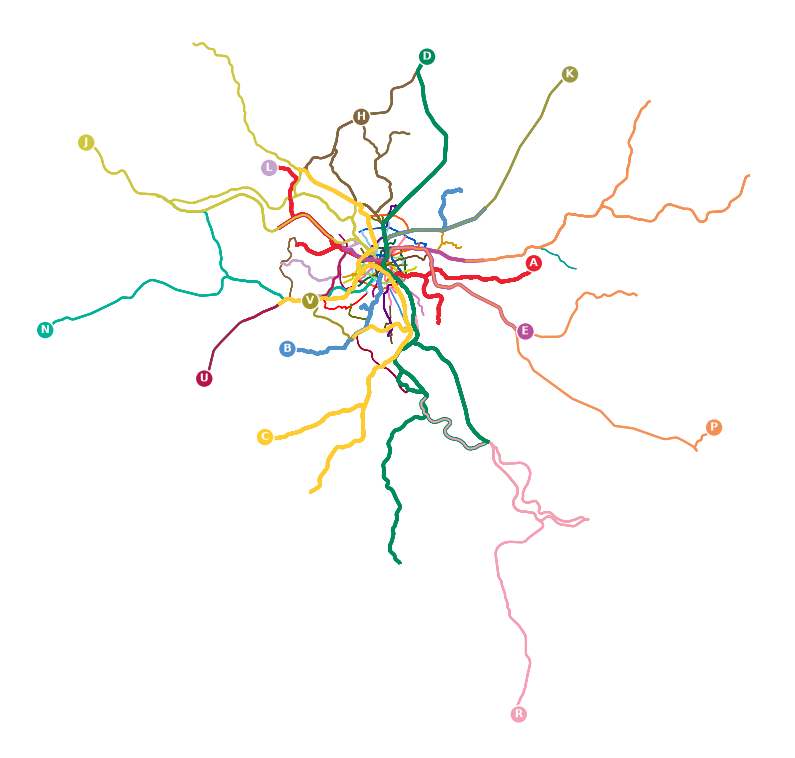

In [ ]:
#NEW 

# ===== CARTE DU RÉSEAU =====
# Toutes les lignes (toutes les branches), sans les arrêts,
# avec le nom des lignes de train (RER + Transilien) au bout de chaque ligne
from shapely.geometry import Point

# Épaisseur du trait selon le type de ligne
EPAISSEUR = {"metro": 1, "tram": 0.8, "transilien": 1.5, "rer": 2.5}

ax = gpd_idfm.plot(
    color="#" + gpd_idfm["route_color"],
    linewidth=gpd_idfm["mode"].map(EPAISSEUR).values,
    figsize=(10, 10),
)

# Nom des lignes de train, placé au terminus le plus loin du centre de Paris
centre_paris = Point(651_000, 6_862_000)
trains = traces[traces["mode"].isin(["rer", "transilien"])]

for _, t in trains.iterrows():
    debut = Point(t.geometry.coords[0])
    fin = Point(t.geometry.coords[-1])
    bout = max([debut, fin], key=lambda p: p.distance(centre_paris))  # le bout le plus éloigné

    ax.annotate(
        t["route_short_name"], (bout.x, bout.y),
        ha="center", va="center", fontsize=8, fontweight="bold", color="white",
        bbox=dict(boxstyle="circle,pad=0.3", facecolor="#" + t["route_color"], edgecolor="white"),
        zorder=6,
    )

ax.set_axis_off()
plt.savefig("carte_lignes_idfm.png", dpi=300, bbox_inches="tight")
plt.show()

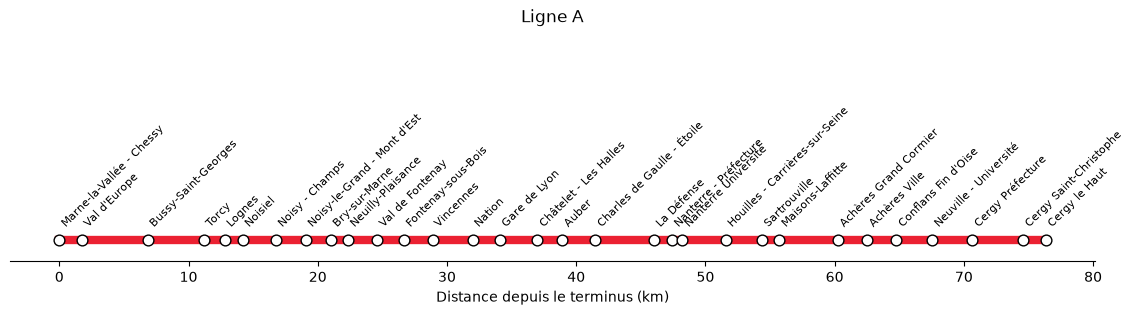

In [40]:
# ===== SCHÉMA D'UNE LIGNE =====
# La ligne "à plat", comme les plans dans le métro
num = "A"  # numéro de la ligne à afficher (rer ou metro)
arrets = stations[stations["route_short_name"] == num]
couleur = "#" + arrets["route_color"].iloc[0]

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6)
ax.scatter(arrets["position_km"], [0] * len(arrets),
           color="white", edgecolor="black", s=60, zorder=3)

# Noms des stations, inclinés au-dessus de la ligne
for _, a in arrets.iterrows():
    ax.annotate(a["stop_name"], xy=(a["position_km"], 0), xytext=(0, 8),
                textcoords="offset points", rotation=45, fontsize=8,
                ha="left", va="bottom")

ax.set_title(f"Ligne {num}")
ax.set_xlabel("Distance depuis le terminus (km)")
ax.set_yticks([])
ax.set_ylim(-0.1, 1)
ax.spines[["left", "top", "right"]].set_visible(False)
plt.show()

# Partie 2 : Les actifs franciliens et leurs trajets (MOBPRO)

In [41]:
#  A 
#  CHARGEMENT ET PRÉPARATION DE MOBPRO 
df_mob = pd.read_parquet("RP2023_mobpro.parquet")

# On garde seulement l'Île-de-France (code région 11)
df_mob = df_mob[df_mob["REGION"].astype(str) == "11"].copy()

# Codes en texte, pour pouvoir les comparer aux dictionnaires
df_mob["COMMUNE"] = df_mob["COMMUNE"].astype(str)
df_mob["GS"] = df_mob["GS"].astype(str)        # GS = CSP
df_mob["TRANS"] = df_mob["TRANS"].astype(str)  # TRANS = mode de transport

# Noms en clair
noms_csp = {
    "1": "Agriculteurs",
    "2": "Artisans, commerçants, chefs d'entreprise",
    "3": "Cadres",
    "4": "Professions intermédiaires",
    "5": "Employés",
    "6": "Ouvriers",
}
noms_mode = {
    "1": "Pas de transport",
    "2": "Marche",
    "3": "Vélo",
    "4": "Deux-roues motorisé",
    "5": "Voiture",
    "6": "Transports en commun",
}
df_mob["CSP"] = df_mob["GS"].map(noms_csp)
df_mob["mode"] = df_mob["TRANS"].map(noms_mode)

# True si la personne va travailler en transports en commun
df_mob["tc"] = df_mob["mode"] == "Transports en commun"

# Code géographique : l'arrondissement si on habite Paris, sinon la commune
df_mob["code_geo"] = np.where(
    df_mob["COMMUNE"] == "75056", df_mob["ARM"].astype(str), df_mob["COMMUNE"]
)

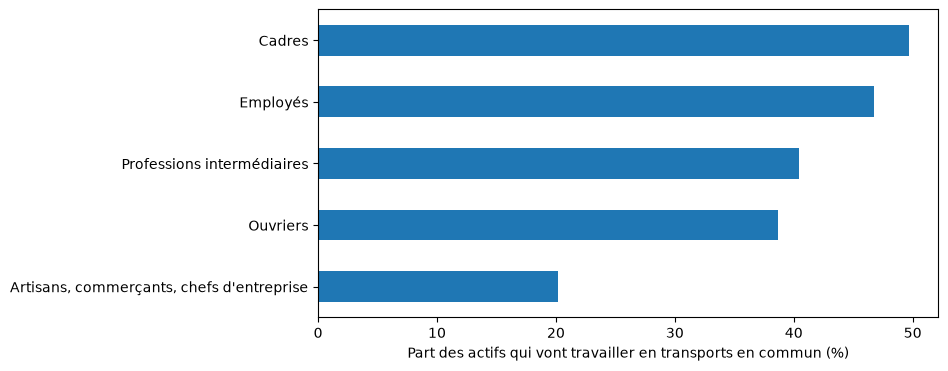

In [42]:
#  B 
#  PART DES TRANSPORTS EN COMMUN PAR CSP 
# Pondéré par IPONDI : chaque ligne représente plusieurs personnes réelles
df_mob["poids_tc"] = df_mob["IPONDI"] * df_mob["tc"]
somme = df_mob.groupby("CSP")[["poids_tc", "IPONDI"]].sum()
part_tc = somme["poids_tc"] / somme["IPONDI"] * 100

part_tc = part_tc.drop("Agriculteurs")  # trop peu nombreux pour être fiables

ax = part_tc.sort_values().plot(kind="barh", color="#1f77b4", figsize=(8, 4))
ax.set_xlabel("Part des actifs qui vont travailler en transports en commun (%)")
ax.set_ylabel("")
plt.show()

# Partie 3 : Croiser le réseau et la population

In [14]:
# C 
#  CONTOURS DES COMMUNES ET DES ARRONDISSEMENTS 

# Communes d'Île-de-France (fichier public GitHub)
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions/ile-de-france/communes-ile-de-france.geojson"
communes = gpd.read_file(url)
communes = communes.rename(columns={"code": "INSEE_COM"})
communes = communes.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# Arrondissements de Paris (open data de la Ville de Paris)
url_arr = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/arrondissements/exports/geojson"
arr = gpd.read_file(url_arr)
arr = arr.rename(columns={"c_arinsee": "INSEE_COM"})
arr["INSEE_COM"] = arr["INSEE_COM"].astype(int).astype(str)  # ex : "75113"
arr["nom"] = arr["INSEE_COM"].str[-2:].astype(int).map(lambda n: "1er" if n == 1 else f"{n}ème")
arr = arr.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# On remplace "Paris" (75056) par ses 20 arrondissements
communes = pd.concat([communes[communes["INSEE_COM"] != "75056"], arr], ignore_index=True)

In [15]:
#  D
#  FONCTION - PART D'UN INDICATEUR PAR COMMUNE 

def part_par_zone(df_mob, indicateur):
    """Part (en %) d'un indicateur parmi les actifs de chaque commune
    (ou de chaque arrondissement pour Paris).
    indicateur : une CSP ("Ouvriers", "Cadres"...) ou "Transports en commun"."""
    # True pour les personnes concernées par l'indicateur
    if indicateur == "Transports en commun":
        cible = df_mob["tc"]
    else:
        cible = df_mob["CSP"] == indicateur

    # Part pondérée : poids des personnes concernées / poids de tous les actifs
    somme_cible = (df_mob["IPONDI"] * cible).groupby(df_mob["code_geo"]).sum()
    somme_total = df_mob.groupby("code_geo")["IPONDI"].sum()
    return (somme_cible / somme_total * 100).round(1).rename("part")

In [57]:
#  E 
#  COMMUNE DE CHAQUE STATION 
# Jointure géographique : on cherche la commune (ou l'arrondissement) qui contient chaque station
stations_com = gpd.sjoin(
    stations.drop(columns=["trace"]),  # colonne du tracé inutile ici
    communes,
    predicate="within",
)

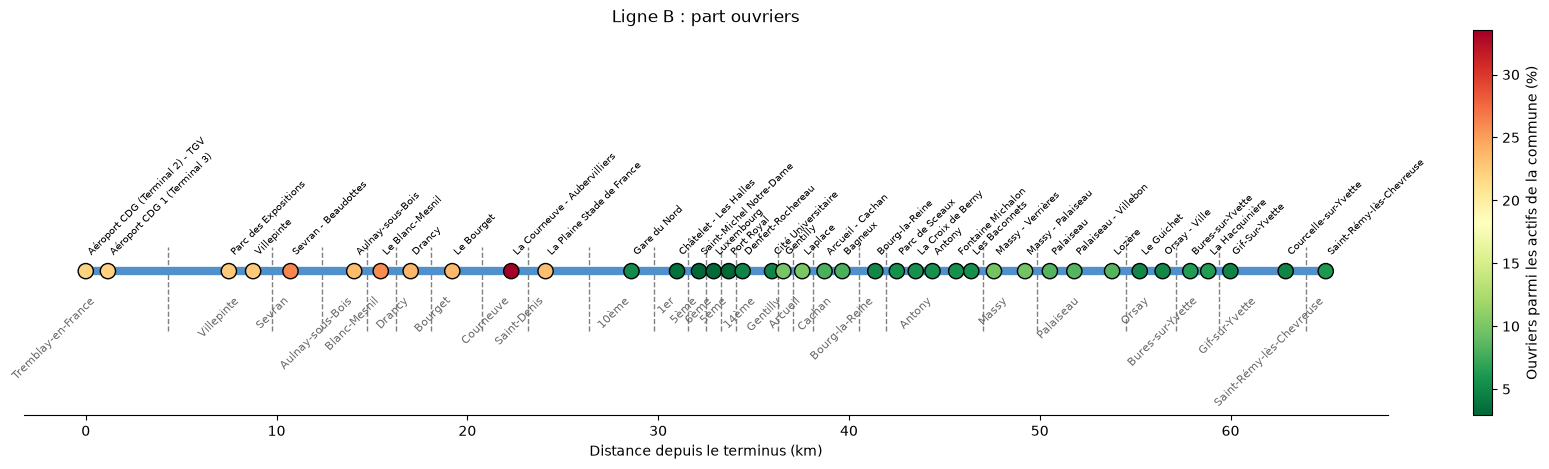

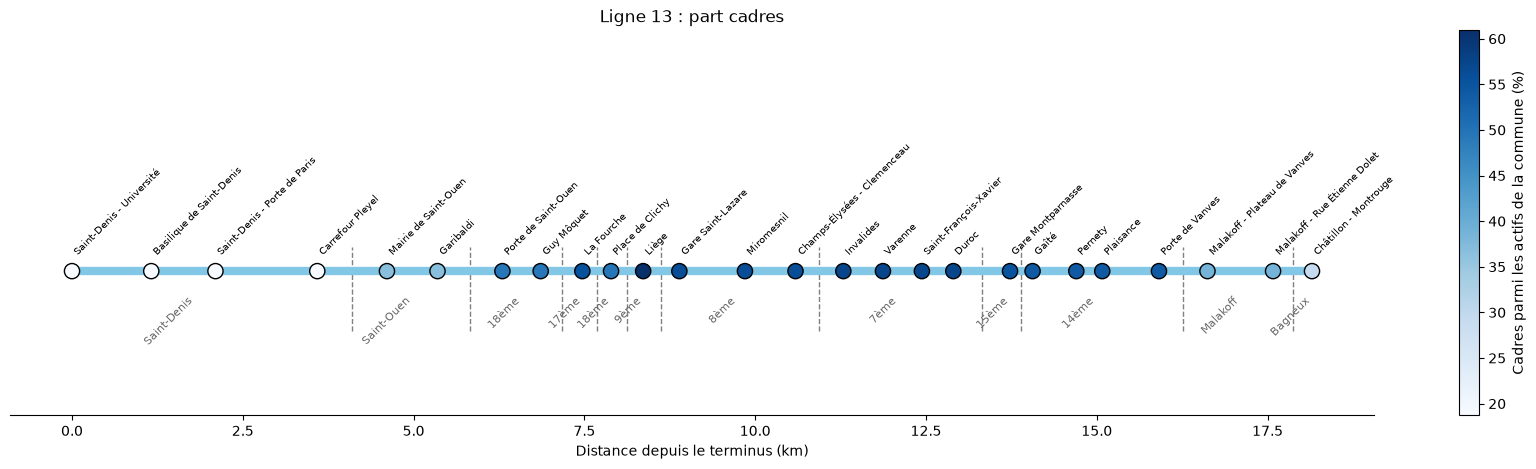

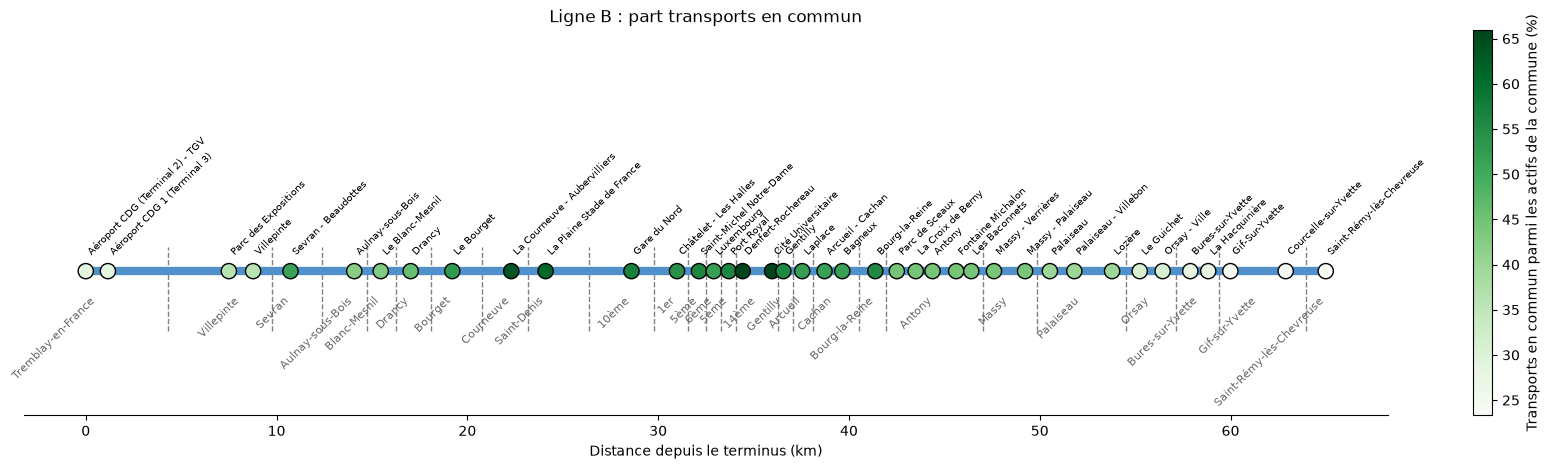

In [58]:
# F 
# FONCTION - SCHÉMA DE LIGNE COLORÉ PAR UN INDICATEUR 

def schema_ligne(num, indicateur="Ouvriers", cmap="RdYlGn_r"):
    """Schéma d'une ligne "à plat", stations colorées selon un indicateur.
    num        : numéro de la ligne ("13", "B"...)
    indicateur : une CSP ("Ouvriers", "Cadres"...) ou "Transports en commun" """

    # Stations de la ligne, dans l'ordre, avec la valeur de l'indicateur de leur commune
    part = part_par_zone(df_mob, indicateur)
    arrets = stations_com[stations_com["route_short_name"] == num]
    arrets = arrets.merge(part, left_on="INSEE_COM", right_index=True, how="left")
    arrets = arrets.sort_values("position_km").reset_index(drop=True)
    couleur = "#" + arrets["route_color"].iloc[0]

    fig, ax = plt.subplots(figsize=(22, 5))
    ax.plot(arrets["position_km"], [0] * len(arrets), color=couleur, linewidth=6, zorder=1)
    points = ax.scatter(
        arrets["position_km"], [0] * len(arrets),
        c=arrets["part"], cmap=cmap,
        s=120, edgecolor="black", zorder=2,
    )

    # Noms des stations, au-dessus
    for _, a in arrets.iterrows():
        ax.annotate(a["stop_name"], xy=(a["position_km"], 0), xytext=(0, 10),
                    textcoords="offset points", rotation=45, fontsize=7,
                    ha="left", va="bottom")

    # Délimitation des communes : un "bloc" = des stations consécutives dans la même commune
    arrets["bloc"] = (arrets["nom"] != arrets["nom"].shift()).cumsum()
    blocs = arrets.groupby("bloc").agg(
        nom=("nom", "first"),
        debut=("position_km", "min"),
        fin=("position_km", "max"),
    )

    # Trait pointillé à mi-chemin entre deux communes
    for i in range(len(blocs) - 1):
        frontiere = (blocs["fin"].iloc[i] + blocs["debut"].iloc[i + 1]) / 2
        ax.vlines(frontiere, -0.25, 0.1, color="gray", linestyle="--", linewidth=1, zorder=0)

    # Nom de la commune, en dessous
    for _, b in blocs.iterrows():
        ax.text((b["debut"] + b["fin"]) / 2, -0.1, b["nom"],
                rotation=45, ha="right", va="top", fontsize=8, color="dimgray")

    fig.colorbar(points, ax=ax, label=f"{indicateur} parmi les actifs de la commune (%)")
    ax.set_title(f"Ligne {num} : part {indicateur.lower()}")
    ax.set_xlabel("Distance depuis le terminus (km)")
    ax.set_ylim(-0.6, 1)
    ax.set_yticks([])
    ax.spines[["left", "top", "right"]].set_visible(False)
    plt.show()


# Exemples
schema_ligne("B", "Ouvriers")
schema_ligne("13", "Cadres", cmap="Blues")
schema_ligne("B", "Transports en commun", cmap="Greens")

In [59]:
# NEW

#  G 
#  FONCTION - CARTE DE PARIS OU DE L'ÎLE-DE-FRANCE =====

# Contours des départements : on fusionne les communes selon les 2 premiers chiffres du code
communes["dep"] = communes["INSEE_COM"].str[:2]
departements = communes.dissolve(by="dep").reset_index()[["dep", "geometry"]]


def carte(indicateur="Ouvriers", zone="paris", ligne=None, reseau=False, cmap="Reds"):
    """Carte colorée selon un indicateur (en % des actifs).
    zone   : "paris" (20 arrondissements) ou "idf" (toutes les communes)
    ligne  : numéro d'une ligne à superposer, par exemple "13" ou "P" (facultatif)
    reseau : True pour tout le réseau, ou une liste de types, ex. ["rer", "transilien"]"""

    # 1. Le fond de carte selon la zone choisie
    if zone == "paris":
        fond = arr
    elif zone == "idf":
        fond = communes
    else:
        raise ValueError('zone doit valoir "paris" ou "idf"')

    # On ajoute la valeur de l'indicateur à chaque zone
    part = part_par_zone(df_mob, indicateur)
    fond = fond.merge(part, left_on="INSEE_COM", right_index=True, how="left")

    ax = fond.plot(
        column="part", cmap=cmap, legend=True,
        edgecolor="white",
        linewidth=0.8 if zone == "paris" else 0.1,  # traits fins pour les 1 300 communes
        figsize=(12, 10),
        missing_kwds={"color": "lightgrey"},  # gris si pas de donnée
        legend_kwds={"label": f"{indicateur} parmi les actifs (%)", "shrink": 0.6},
    )

    # 2a. Paris : nom et valeur de chaque arrondissement
    if zone == "paris":
        for _, r in fond.iterrows():
            p = r.geometry.representative_point()
            ax.annotate(f"{r['nom']}\n{r['part']} %", (p.x, p.y),
                        ha="center", va="center", fontsize=7)

    # 2b. IDF : contours des départements en noir + leur numéro
    if zone == "idf":
        departements.boundary.plot(ax=ax, color="black", linewidth=1, zorder=2)
        for _, d in departements.iterrows():
            p = d.geometry.representative_point()
            ax.annotate(d["dep"], (p.x, p.y), ha="center", va="center",
                        fontsize=11, fontweight="bold", color="black")

    # 3a. Le réseau (facultatif), sans les arrêts
    if reseau:
        lignes = gpd_idfm if reseau is True else gpd_idfm[gpd_idfm["mode"].isin(reseau)]
        epaisseur = lignes["mode"].map(EPAISSEUR).values  # EPAISSEUR est défini en Partie 1
        lignes.plot(ax=ax, color="white", linewidth=epaisseur + 1.5, zorder=3)  # liseré blanc
        lignes.plot(ax=ax, color="#" + lignes["route_color"], linewidth=epaisseur, zorder=4)

    # 3b. Une seule ligne (facultative), avec un liseré blanc, et ses stations
    if ligne is not None:
        trace = gpd_idfm[gpd_idfm["route_short_name"] == ligne]
        trace.plot(ax=ax, color="white", linewidth=7, zorder=3)
        trace.plot(ax=ax, color="#" + trace["route_color"].iloc[0], linewidth=4, zorder=4)
        gpd_stations[gpd_stations["route_short_name"] == ligne].plot(
            ax=ax, color="white", edgecolor="black", markersize=30, zorder=5
        )

    # 4. Cadrage sur la zone (marge de 500 m)
    xmin, ymin, xmax, ymax = fond.total_bounds
    ax.set_xlim(xmin - 500, xmax + 500)
    ax.set_ylim(ymin - 500, ymax + 500)

    # Titre
    nom_zone = "Paris" if zone == "paris" else "Île-de-France"
    titre = f"Part {indicateur.lower()} parmi les actifs ({nom_zone})"
    if ligne is not None:
        titre += f" - ligne {ligne}"
    if reseau:
        titre += " - réseau"
    ax.set_title(titre)
    ax.set_axis_off()
    plt.show()

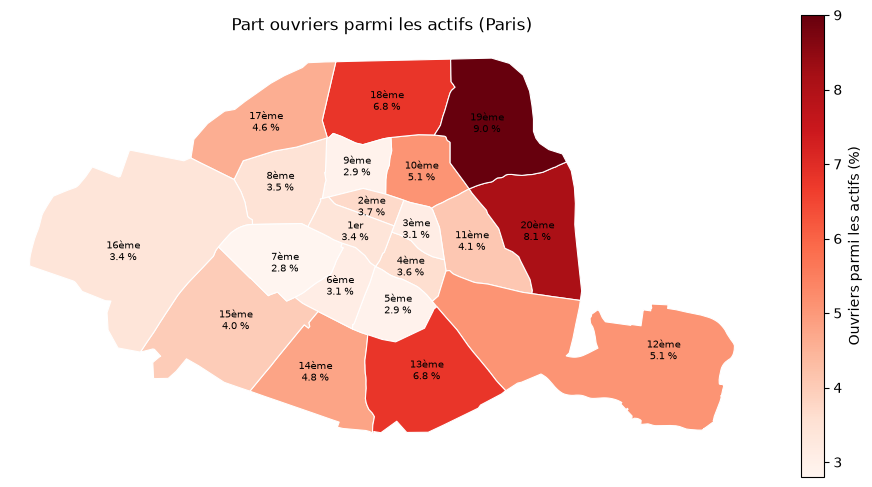

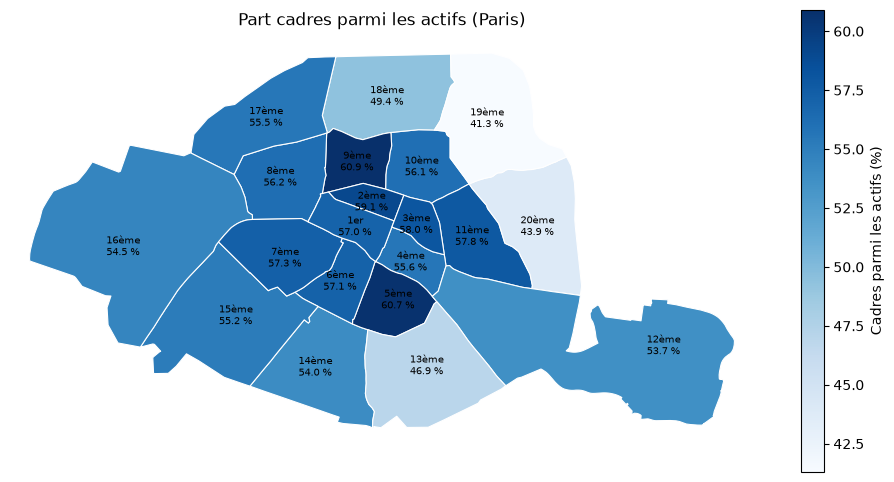

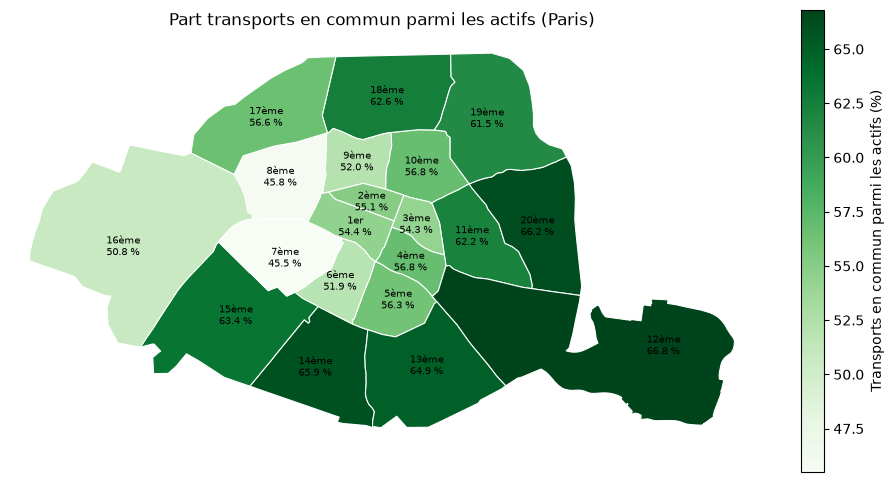

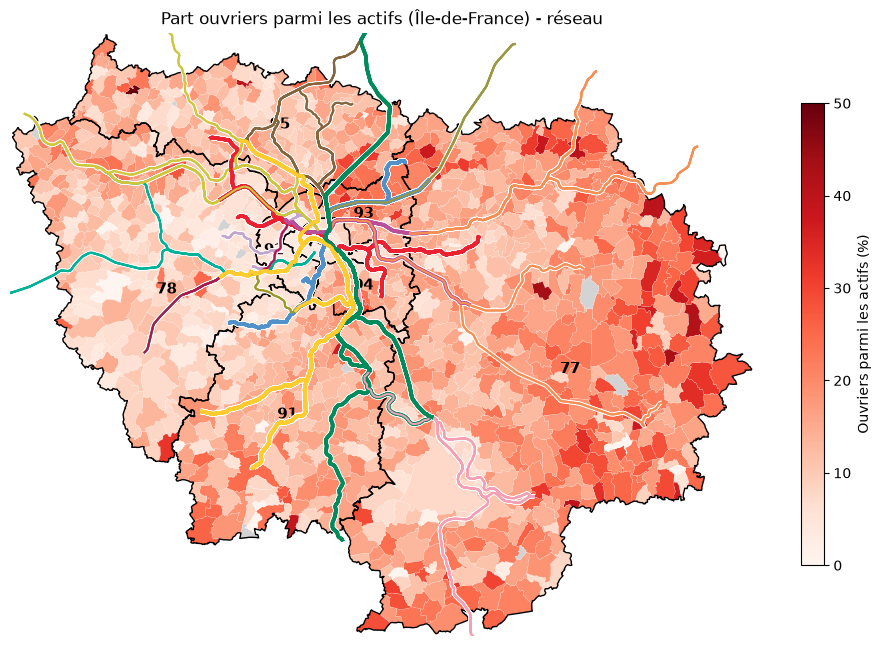

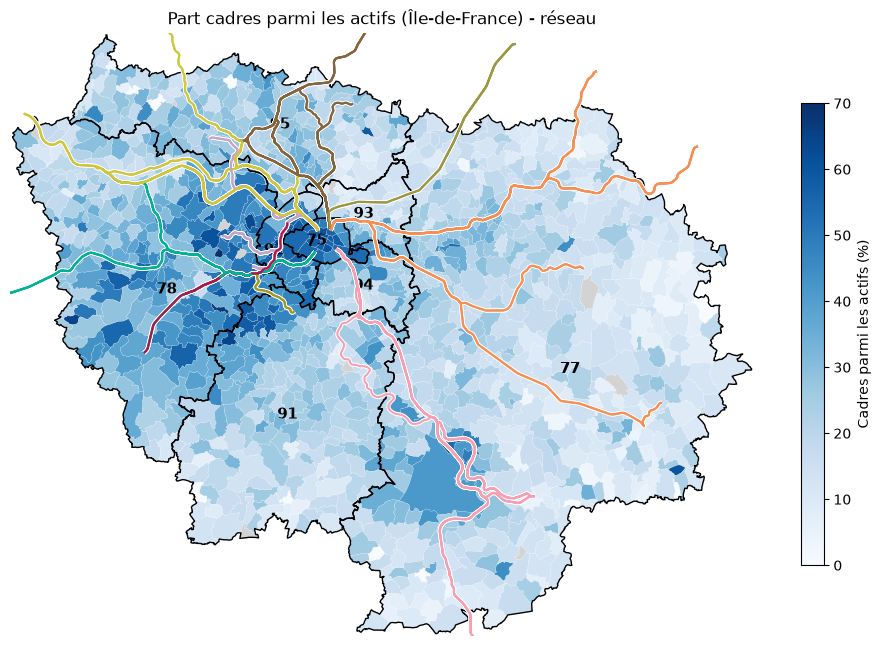

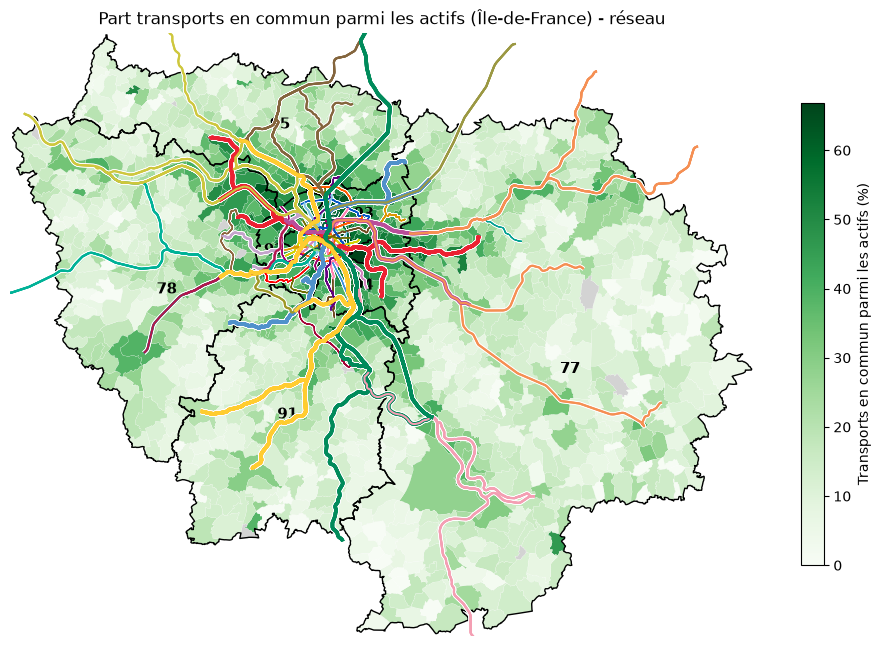

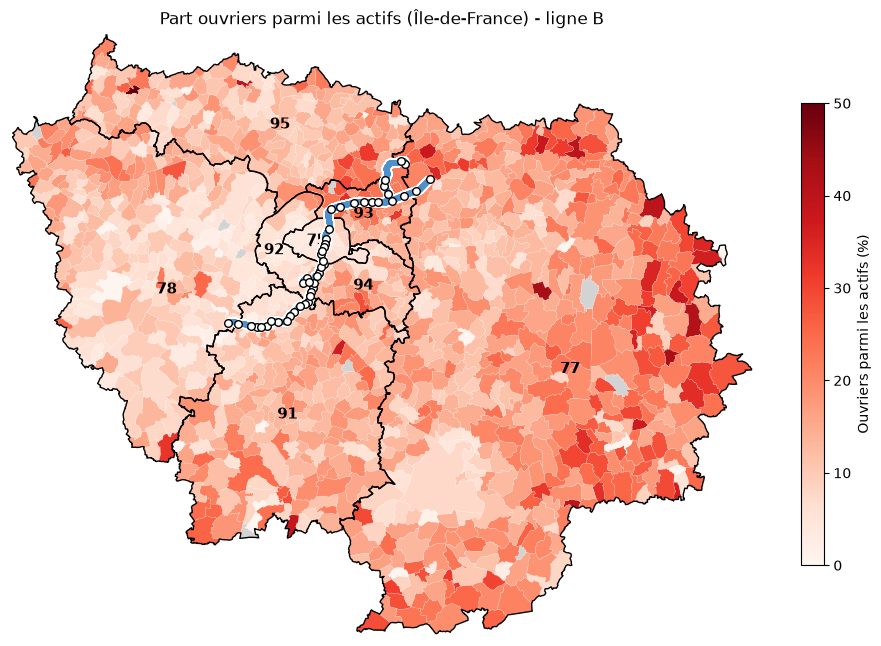

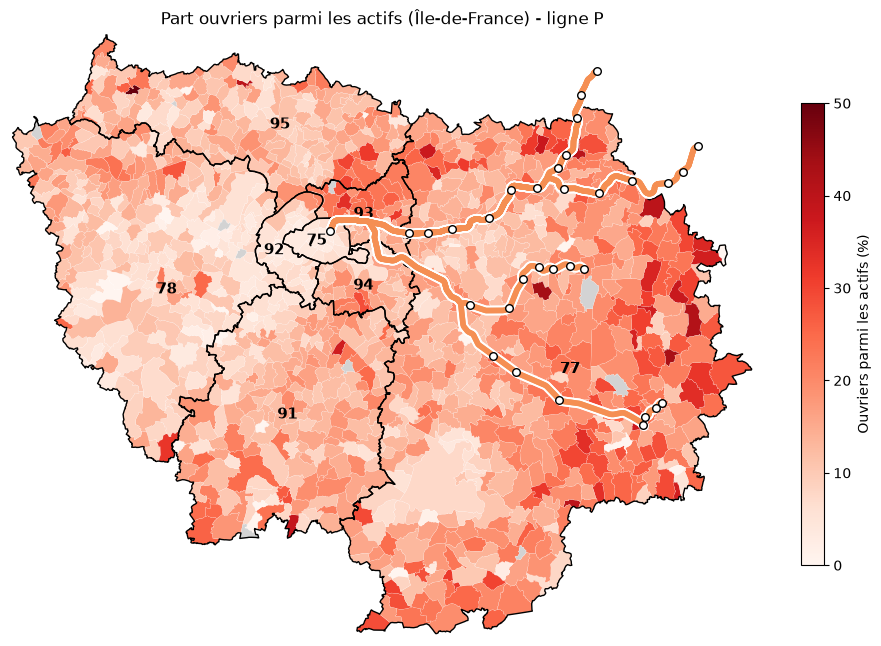

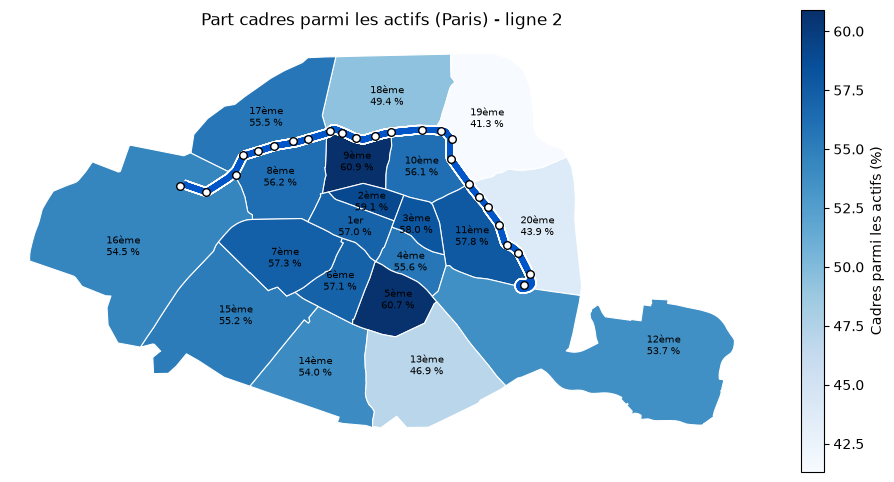

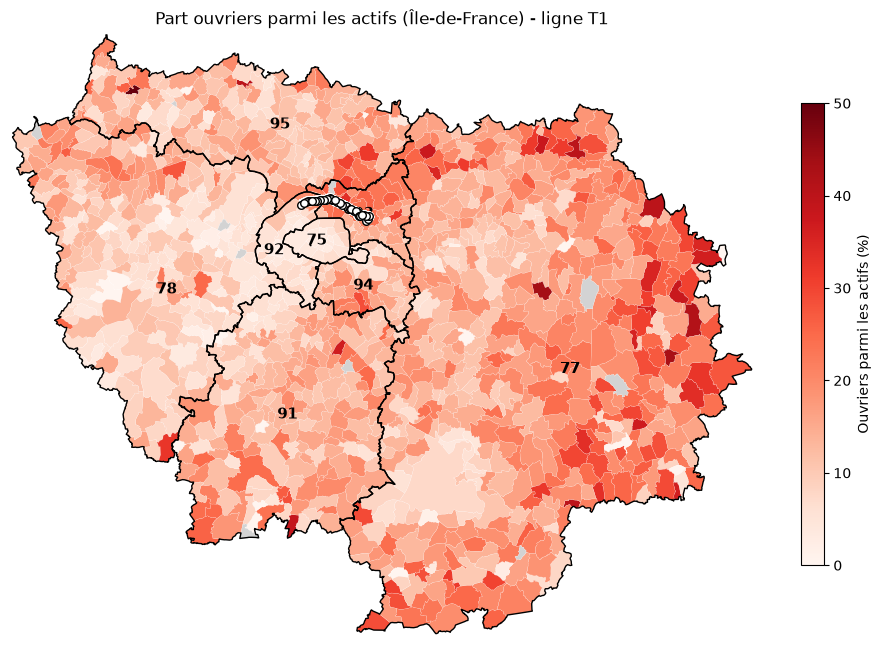

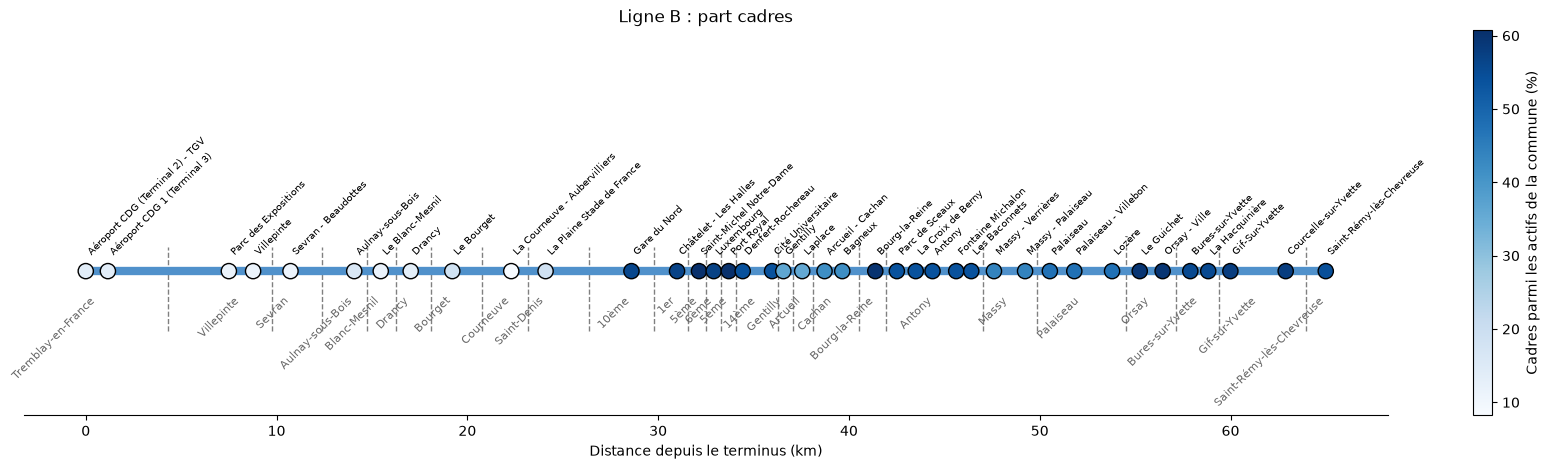

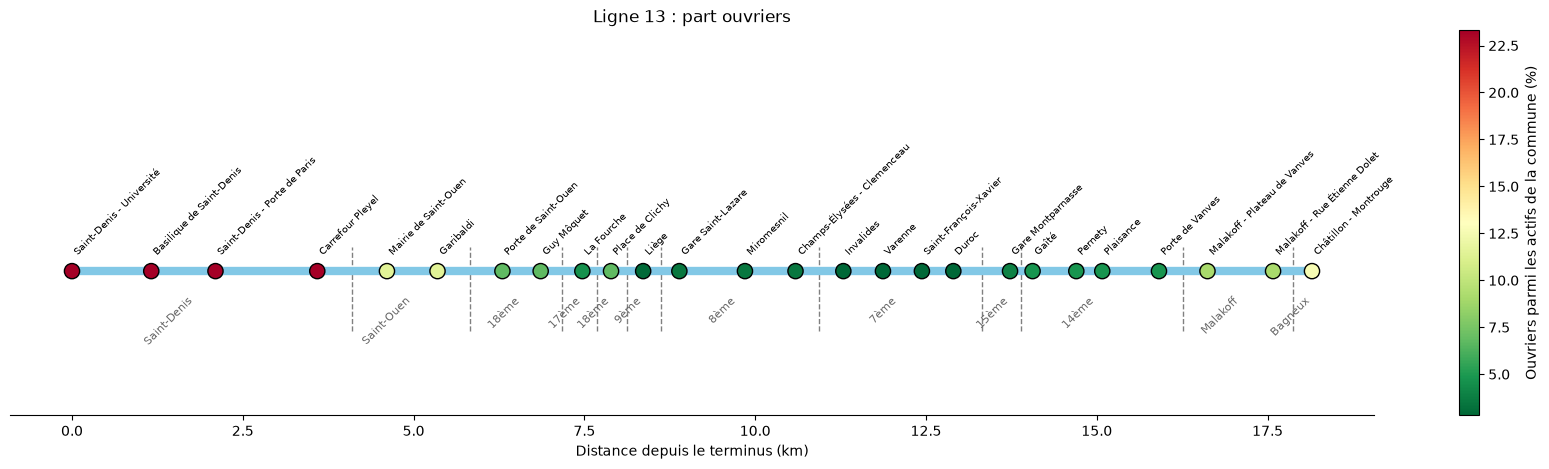

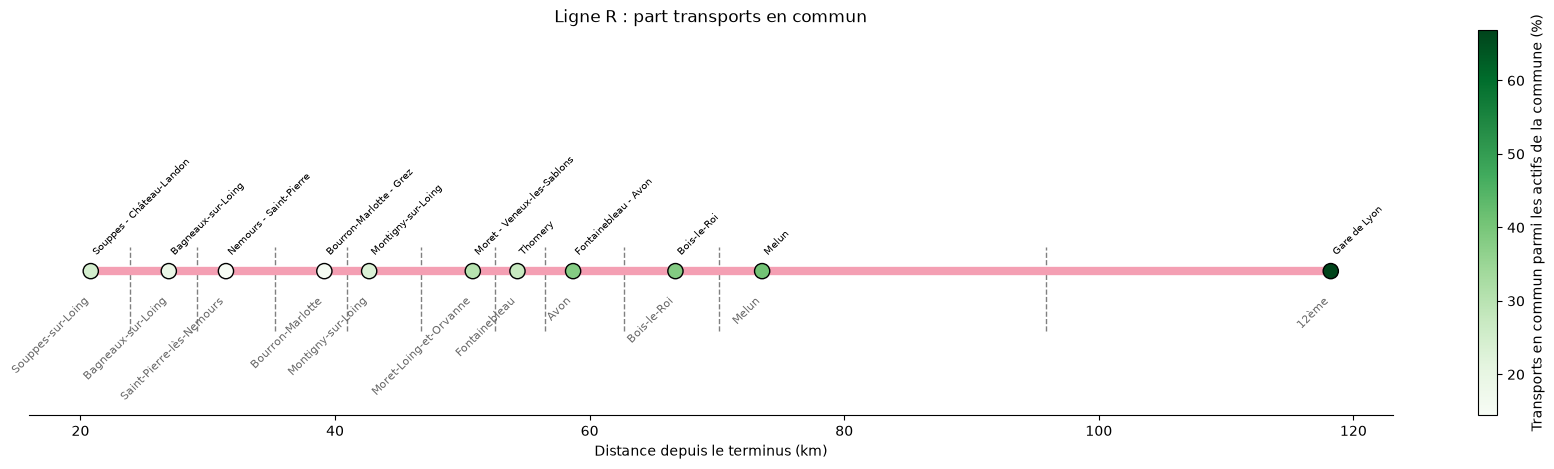

In [60]:
#  H 
#  CARTES 

# --- 1. Paris par arrondissement : les 3 indicateurs principaux ---
carte("Ouvriers", zone="paris")
carte("Cadres", zone="paris", cmap="Blues")
carte("Transports en commun", zone="paris", cmap="Greens")

# --- 2. Île-de-France avec le réseau ---
carte("Ouvriers", zone="idf", reseau=["rer", "transilien"])        # tous les trains
carte("Cadres", zone="idf", reseau=["transilien"], cmap="Blues")   # Transilien seul
carte("Transports en commun", zone="idf", reseau=True, cmap="Greens")  # tout le réseau

# --- 3. Une seule ligne, de chaque type ---
carte("Ouvriers", zone="idf", ligne="B")                    # RER
carte("Ouvriers", zone="idf", ligne="P")                    # Transilien
carte("Cadres", zone="paris", ligne="2", cmap="Blues")      # métro, sur Paris
carte("Ouvriers", zone="idf", ligne="T1")                   # tram

# --- 4. Schémas de ligne "à plat" ---
schema_ligne("B", "Cadres", cmap="Blues")                   # contraste nord / sud
schema_ligne("13", "Ouvriers")                              # Saint-Denis -> Paris -> Châtillon
schema_ligne("R", "Transports en commun", cmap="Greens")    # Transilien vers la grande couronne